# **Lab 8: Sequence Modelling with CNNs and RNNs in PyTorch**

# **Objective:**

To compare convolutional (CNN) and recurrent (RNN / GRU / LSTM) architectures in PyTorch, and to understand when each one is appropriate.

# **Outline:**

1. **Data Loading**
* Load the Fashion-MNIST dataset.
* Visualize sample images.
* Perform one-hot encoding of target labels.
2. **Data Splitting**
* Split the training data into training and validation sets (80%-20%). Keep the official test set for final evaluation.
3. **Create Dataloaders**
4. **Design a CNN**
* 4 convolutional layers with ReLU; Max Pooling after every 2 layers.
5. **Design an RNN**
* Treat each 28x28 image as a *sequence of 28 rows*, each row a 28-dim vector. Feed it to a vanilla RNN / GRU / LSTM and classify from the last hidden state.
6. **Loss Function**
7. **Model Training**
* Train with SGD (momentum), record training and validation loss every epoch, save the best model.
8. **Loss Plots**
9. **Model Evaluation**
* Classification report and confusion matrix on the test set.
10. **CNN vs RNN Comparison**
* Parameter count, test accuracy, training time.

In [ ]:
import time                                                      # for timing training runs
import numpy as np                                               # numerical arrays
import torch                                                     # core PyTorch library
import torchvision                                               # datasets/transforms for vision
import torchvision.transforms as transforms                      # image preprocessing pipeline
import torch.nn as nn                                             # neural network layers
import torch.nn.functional as F                                   # functional ops (relu, one_hot, etc.)
import torch.optim as optim                                       # optimizers (SGD, Adam, ...)
import matplotlib.pyplot as plt                                   # plotting
import seaborn as sns                                             # nicer heatmaps for the confusion matrix
from torch.utils.data import DataLoader, random_split             # batching and train/val splitting
from sklearn.metrics import classification_report, confusion_matrix, f1_score  # evaluation metrics

torch.manual_seed(42)                                             # seed PyTorch's RNG for reproducibility
np.random.seed(42)                                                # seed NumPy's RNG for reproducibility

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # use GPU if one is available, else CPU
print("Device:", device)                                          # show which device will be used

Device: cuda


## 1. Data Loading

In [ ]:
transform = transforms.Compose([                                  # chain of two preprocessing steps applied to every image
    transforms.ToTensor(),                                         # PIL image -> tensor of shape(1,28,28), scales pixels to [0, 1]
    transforms.Normalize((0.2860,), (0.3530,))   # Fashion-MNIST mean / std  # standardize using dataset mean/std
])

full_train = torchvision.datasets.FashionMNIST(root='./data', train=True,  download=True, transform=transform)  # full 60k training set
testset    = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)  # official 10k test set

classes = full_train.classes                                      # list of class names, indexed by label id
print(f"Number of classes: {len(classes)}")                        # how many distinct labels
print(f"Class names: {classes}")                                   # the class names themselves
print(f"Train samples: {len(full_train)} | Test samples: {len(testset)}")  # sanity-check dataset sizes

image, label = full_train[0]                                      # grab the first (image, label) pair
print("Image shape:", image.shape, "| Label:", label, "->", classes[label])  # check tensor shape and label mapping

Number of classes: 10
Class names: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Train samples: 60000 | Test samples: 10000
Image shape: torch.Size([1, 28, 28]) | Label: 9 -> Ankle boot


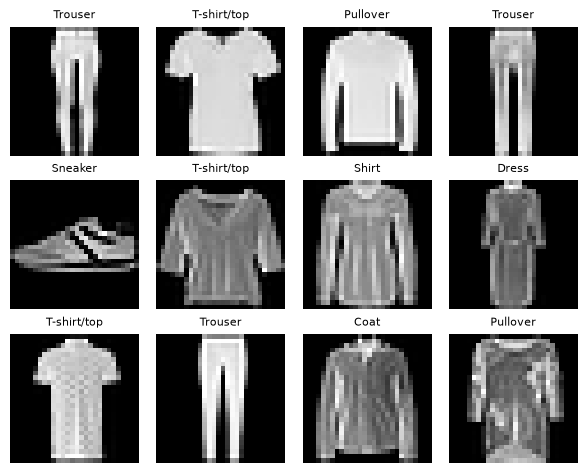

In [ ]:
def imshow(img):                                                  # display one normalized image tensor
    img = img * 0.3530 + 0.2860          # un-normalize             # invert the Normalize() transform
    plt.imshow(img.squeeze().numpy(), cmap='gray')                 # squeeze method drop the channel dim(1x28x28 -> 28x28), plot as grayscale
    plt.axis('off')                                                 # hide axis ticks

def visualize_samples(dataset, num_samples=12, images_per_row=4):   # show a grid of random dataset samples
    num_rows = int(np.ceil(num_samples / images_per_row))            # how many grid rows are needed
    idxs = np.random.choice(len(dataset), num_samples, replace=False)  # random, non-repeating sample indices
    plt.figure(figsize=(images_per_row * 1.5, num_rows * 1.6))         # size the figure to fit the grid
    for i, idx in enumerate(idxs):                                    # loop over the chosen samples
        img, lbl = dataset[idx]                                       # fetch the image and its label
        plt.subplot(num_rows, images_per_row, i + 1)                  # select the grid cell for this image
        imshow(img)                                                   # draw the image
        plt.title(classes[lbl], fontsize=8)                           # label it with the class name
    plt.tight_layout()                                                # avoid overlapping subplots
    plt.show()                                                        # render the figure

visualize_samples(full_train)                                         # run it on the training set

In [ ]:
# One-hot encoding (demonstration only).
# NOTE: nn.CrossEntropyLoss expects integer class indices, NOT one-hot vectors,
# so we keep using the integer labels for training.
train_labels = full_train.targets.clone()                          # copy of all training labels (integers 0-9)
one_hot = F.one_hot(train_labels, num_classes=10).float()           # convert to one-hot vectors, for illustration only

for i in range(5):                                                  # print a few examples
    print(f"label = {train_labels[i].item()} ({classes[train_labels[i]]}) -> {one_hot[i].numpy()}")  # integer label vs. its one-hot form

label = 9 (Ankle boot) -> [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
label = 0 (T-shirt/top) -> [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
label = 0 (T-shirt/top) -> [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
label = 3 (Dress) -> [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
label = 0 (T-shirt/top) -> [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## 2. Data Splitting and 3. Dataloaders

In [ ]:
train_size = int(0.8 * len(full_train))                            # 80% of the 60k training images
val_size   = len(full_train) - train_size                          # remaining 20% for validation
trainset, valset = random_split(full_train, [train_size, val_size],  # randomly split full_train into two subsets
                                generator=torch.Generator().manual_seed(42))  # fixed seed -> reproducible split

print(f"Train: {len(trainset)} | Val: {len(valset)} | Test: {len(testset)}")  # confirm split sizes

train_loader = DataLoader(trainset, batch_size=64,   shuffle=True)   # training batches, reshuffled every epoch
val_loader   = DataLoader(valset,   batch_size=256,  shuffle=False)  # validation batches, order doesn't matter
test_loader  = DataLoader(testset,  batch_size=256,  shuffle=False)  # test batches, order doesn't matter

images, labels = next(iter(train_loader))                           # pull one batch to inspect its shape
print(images.shape, labels.shape)    # (64, 1, 28, 28), (64,)        # confirm batch dimensions

Train: 48000 | Val: 12000 | Test: 10000
torch.Size([64, 1, 28, 28]) torch.Size([64])


## 4. Design a CNN

Full dimension trace for a batch of `B` grayscale `28 x 28` images through `SimpleCNN`:

| Step | Layer | Input shape | Output shape | Why this shape |
|---|---|---|---|---|
| 0 | (raw input) | — | `(B, 1, 28, 28)` | 1 grayscale channel, 28x28 pixels |
| 1 | `conv1`: Conv2d(1→16, k=3, pad=1) + ReLU | `(B, 1, 28, 28)` | `(B, 16, 28, 28)` | `padding=1` with a 3x3 kernel keeps H,W unchanged; channels go 1→16 (16 learned filters) |
| 2 | `conv2`: Conv2d(16→32, k=3, pad=1) + ReLU | `(B, 16, 28, 28)` | `(B, 32, 28, 28)` | same padding trick; channels 16→32 |
| 3 | `pool`: MaxPool2d(2,2) | `(B, 32, 28, 28)` | `(B, 32, 14, 14)` | pooling with a 2x2 window/stride **halves** H and W; channels untouched |
| 4 | `conv3`: Conv2d(32→64, k=3, pad=1) + ReLU | `(B, 32, 14, 14)` | `(B, 64, 14, 14)` | channels 32→64, spatial size unchanged (padding again) |
| 5 | `conv4`: Conv2d(64→128, k=3, pad=1) + ReLU | `(B, 64, 14, 14)` | `(B, 128, 14, 14)` | channels 64→128, spatial size unchanged |
| 6 | `pool`: MaxPool2d(2,2) | `(B, 128, 14, 14)` | `(B, 128, 7, 7)` | halves H,W again: 14→7 |
| 7 | `x.flatten(1)` | `(B, 128, 7, 7)` | `(B, 6272)` | pure reshape, **no learned weights** — just lays out `128 x 7 x 7 = 6272` numbers per image in a row |
| 8 | `fc1`: Linear(6272→128) + ReLU + Dropout | `(B, 6272)` | `(B, 128)` | **learned** weighted sums: each of the 128 outputs = its own weighted combination of all 6272 inputs. 128 is a chosen hidden-layer width, not derived from any formula |
| 9 | `fc2`: Linear(128→num_classes) | `(B, 128)` | `(B, 10)` | final class logits, one raw score per class (no softmax applied here — `CrossEntropyLoss` does that internally during training) |

Key things to notice:
- **Convolutions** (steps 1,2,4,5) change the *channel* count (feature richness) but, thanks to `padding=1` on a 3x3 kernel, leave H and W untouched.
- **Pooling** (steps 3,6) is what actually shrinks H and W — each `MaxPool2d(2,2)` halves both dimensions.
- **Flatten** (step 7) is bookkeeping, not learning — it just unrolls the 3D `(channels, H, W)` feature map into a single 1D vector per image so the fully-connected layers can consume it.
- **Linear layers** (steps 8,9) are where the "how many numbers do I get out" question is answered by *design choice* (128, then `num_classes`), not by any shape arithmetic — each output is a learned weighted sum over every input to that layer.

### The formula behind steps 1–6 (Conv2d / MaxPool2d spatial size)

Both `Conv2d` and `MaxPool2d` compute their output H (and W, symmetrically) the same way:

$$
H_{out} = \left\lfloor \frac{H_{in} + 2P - K}{S} \right\rfloor + 1
$$

where `K` = kernel size, `P` = padding, `S` = stride (PyTorch defaults `stride = kernel_size` for `MaxPool2d` when you only pass one number, and `stride=1` for `Conv2d` unless you set it).

- **Conv layers here** (`k=3, pad=1, stride=1`): $H_{out} = \lfloor (28 + 2{\cdot}1 - 3)/1 \rfloor + 1 = \lfloor 27 \rfloor + 1 = 28$ — size unchanged. This `padding = (k-1)/2` choice is exactly what makes "same" convolutions: output size = input size.
- **Pool layers here** (`k=2, pad=0, stride=2`): $H_{out} = \lfloor (28 + 0 - 2)/2 \rfloor + 1 = \lfloor 13 \rfloor + 1 = 14$ — size halved. In general, `MaxPool2d(2,2)` always halves H and W (integer-divides by the stride).

The flatten step (7) then has no formula beyond simple multiplication — it's just `channels x H x W = 128 x 7 x 7 = 6272` — and the Linear layers (8, 9) have no shape formula at all: their output size is whatever you pass as `out_features` when you construct them.

In [ ]:
class SimpleCNN(nn.Module):                                         # 4-conv-layer CNN for 28x28 grayscale images
    def __init__(self, num_classes=10):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)                  # 1 input channel -> 16 feature maps, 3x3 kernel
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)                 # 16 -> 32 feature maps
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)                 # 32 -> 64 feature maps
        self.conv4 = nn.Conv2d(64, 128, 3, padding=1)                # 64 -> 128 feature maps
        self.pool = nn.MaxPool2d(2, 2)                                # halves spatial dims each time it's applied
        self.dropout = nn.Dropout(0.5)                                # regularization before the final classifier
        self.fc1 = nn.Linear(128 * 7 * 7, 128)                        # flatten 128x7x7 feature map -> 128 features
        self.fc2 = nn.Linear(128, num_classes)                       # 128 features -> class logits

    def forward(self, x):
        x = F.relu(self.conv1(x))                                    # conv1 + activation, still 28x28
        x = self.pool(F.relu(self.conv2(x)))                         # conv2 + activation, then pool -> 14x14
        x = F.relu(self.conv3(x))                                    # conv3 + activation, still 14x14
        x = self.pool(F.relu(self.conv4(x)))                         # conv4 + activation, then pool -> 7x7
        x = x.flatten(1)                                              # flatten all dims except batch -> (B, 6272)
        x = self.dropout(F.relu(self.fc1(x)))                        # fc1 + activation + dropout
        return self.fc2(x)          # raw logits (no softmax)        # final class scores; CrossEntropyLoss applies softmax internally

## 5. Design an RNN

### The idea: an image as a sequence of rows

Instead of treating the image as a 2D grid (like the CNN does), `SeqRNN` reinterprets each `28 x 28` image as a **sequence of 28 time steps**, where time step `t` is simply **row `t`** of the image — a 28-dimensional vector of pixel values (one value per column). So "reading" the image means scanning it **top row to bottom row**, exactly the way an RNN would read a sentence word by word.

### How one image actually flows through the RNN, step by step

At every time step `t` (t = 1 ... 28), the recurrent cell takes two inputs — the current row `x_t` (28 pixel values) and the hidden state `h_{t-1}` carried over from the previous row — and produces a new hidden state:

$$h_t = f(W_{xh}\,x_t + W_{hh}\,h_{t-1} + b)$$

(`nn.LSTM`/`nn.GRU` replace this single equation with several *gated* versions of it — e.g. LSTM also keeps a cell state `c_t` and uses forget/input/output gates — but the shape contract and the "carry information forward one row at a time" idea are identical; that's why one `SeqRNN` class can swap between `nn.RNN`, `nn.GRU`, `nn.LSTM` just by changing which class is instantiated.)

Concretely, for a single image:
1. **t=1**: feed row 1 (top row, 28 pixels) as `x_1`. Combined with the initial hidden state `h_0` (zeros by default), compute `h_1`. At this point `h_1` only "knows about" row 1.
2. **t=2**: feed row 2 as `x_2`, combined with `h_1` (not raw row 1 — only the compressed hidden state survives). Compute `h_2`, which now reflects rows 1–2.
3. **... repeat for every row ...**
4. **t=28**: feed the last row as `x_28`, combined with `h_27`. Compute `h_28` — by now, `h_28` has (in principle) been shaped by all 28 rows, top to bottom, so it acts as a **compressed summary of the entire image**.

Since `SeqRNN` uses `num_layers=2`, there are actually two of these recurrent passes stacked: layer 1 processes the raw 28-dim row vectors into a sequence of layer-1 hidden states, and layer 2 treats *that whole sequence* as its own input, producing a second, higher-level sequence of hidden states. `out` (returned by `self.rnn(x)`) holds layer 2's hidden state at **every** time step; the model then keeps only the very last one (`out[:, -1, :]`, i.e. `h_28` from the top layer) as "the" summary vector, and feeds it to a linear classifier.

### Dimension trace for a batch of `B` images

| Step | Operation | Input shape | Output shape | Notes |
|---|---|---|---|---|
| 0 | raw input | — | `(B, 1, 28, 28)` | 1 channel, 28 rows x 28 columns |
| 1 | `x.squeeze(1)` | `(B, 1, 28, 28)` | `(B, 28, 28)` | drop the channel dim → `(batch, seq_len=28, features=28)`, i.e. 28 time steps of 28-dim row vectors |
| 2 | `self.rnn(x)` (2-layer LSTM/GRU/RNN, `hidden_size=128`) | `(B, 28, 28)` | `out: (B, 28, 128)` | `out` holds the top layer's hidden state at **every** one of the 28 time steps; this step runs the row-by-row loop described above |
| 3 | `out[:, -1, :]` | `(B, 28, 128)` | `(B, 128)` | keep only the **last** time step's hidden state (`h_28`) — the full-image summary — and discard the other 27 |
| 4 | `self.fc` : Linear(128→num_classes) | `(B, 128)` | `(B, 10)` | final class logits (learned weighted sums, same idea as the CNN's `fc1`/`fc2` — no formula, 10 is just `num_classes`) |

Note the contrast with the CNN's dimension trace: there, *spatial size* shrinks step by step (28→14→7) while *channels* grow (1→16→32→64→128). Here, the sequence length stays fixed at 28 throughout (every row gets visited), and it's the **hidden_size** (28→128) that represents how much the model compresses each row's information — then at the end, 27 of the 28 time steps are thrown away and only the final hidden state carries forward.

`nn.RNN`, `nn.GRU` and `nn.LSTM` share this exact same interface (same input/output shapes), so one class (`SeqRNN` below) covers all three — only the internals of step 2 differ.

In [ ]:
class SeqRNN(nn.Module):                                             # wraps RNN/GRU/LSTM behind one shared interface
    def __init__(self, rnn_type='lstm', input_size=28, hidden_size=128,
                 num_layers=2, num_classes=10, dropout=0.3):
        super().__init__()
        rnn_cls = {'rnn': nn.RNN, 'gru': nn.GRU, 'lstm': nn.LSTM}[rnn_type]  # pick the recurrent cell class by name
        self.rnn = rnn_cls(input_size, hidden_size, num_layers,       # build the recurrent stack
                           batch_first=True, dropout=dropout)         # batch dim first; dropout applied between layers
        self.fc = nn.Linear(hidden_size, num_classes)                 # map final hidden state -> class logits

    def forward(self, x):
        x = x.squeeze(1)              # (B, 1, 28, 28) -> (B, 28, 28) = (batch, seq_len, features)  # drop channel dim, treat rows as time steps
        out, _ = self.rnn(x)          # out: (B, 28, hidden)           # run the sequence through the recurrent layer(s)
        return self.fc(out[:, -1, :]) # last time step -> logits       # classify from the final time step's hidden state

def count_params(m):                                                  # count trainable parameters in a model
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

for name, m in [('CNN', SimpleCNN()), ('RNN', SeqRNN('rnn')), ('GRU', SeqRNN('gru')), ('LSTM', SeqRNN('lstm'))]:  # build one of each model
    print(f"{name:5s} parameters: {count_params(m):,}")               # print its parameter count

CNN   parameters: 901,386
RNN   parameters: 54,538
GRU   parameters: 161,034
LSTM  parameters: 214,282


## 6. Loss Function and 7. Model Training

In [ ]:
criterion = nn.CrossEntropyLoss()                                    # combines softmax + negative log-likelihood

def run_epoch(model, loader, optimizer=None, clip=None):             # one pass over `loader`; trains if optimizer is given
    train = optimizer is not None                                    # training mode iff an optimizer was passed
    model.train(train)                                                # toggle dropout/batchnorm behaviour accordingly
    total, n = 0.0, 0                                                 # running loss sum and sample count
    with torch.set_grad_enabled(train):                               # only build the autograd graph when training
        for x, y in loader:                                           # iterate over mini-batches. this loop always executes
            x, y = x.to(device), y.to(device)                         # move data to the training device
            if train:
                optimizer.zero_grad()                                 # clear gradients from the previous batch before computing new ones.
            loss = criterion(model(x), y)                             # forward pass + loss computation
            if train:
                loss.backward()                                       # backpropagate gradients
                if clip:
                    nn.utils.clip_grad_norm_(model.parameters(), clip)   # stabilises RNN training  # cap gradient norm to avoid exploding gradients
                optimizer.step()                                       # apply the parameter update
            total += loss.item() * x.size(0)                          # accumulate loss weighted by batch size
            n += x.size(0)                                             # accumulate number of samples seen
    return total / n                                                   # mean loss over the whole loader

def train_model(model, name, epochs=15, lr=0.05, momentum=0.9, clip=None):  # full training loop for one model
    model.to(device)                                                   # move model to the training device
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)  # SGD with momentum
    tr_losses, va_losses, best = [], [], float('inf')                  # loss history lists + best val loss so far
    t0 = time.time()                                                   # start the training timer
    for ep in range(epochs):                                           # loop over epochs
        tr = run_epoch(model, train_loader, optimizer, clip)           # one training pass (updates weights)
        va = run_epoch(model, val_loader)                              # one validation pass (no optimizer -> no updates)
        tr_losses.append(tr); va_losses.append(va)                     # record both losses for this epoch
        if va < best:                                   # keep the best checkpoint   # only save when val loss improves
            best = va                                                  # update the best-so-far marker
            torch.save(model.state_dict(), f'{name}.pth')              # persist model weights to disk
        print(f"[{name}] Epoch {ep+1:2d}/{epochs} | train {tr:.4f} | val {va:.4f}")  # progress log
    return tr_losses, va_losses, time.time() - t0                      # return loss histories + elapsed time

history = {}                                                           # collects (train_losses, val_losses, time) per model
cnn = SimpleCNN()                                                      # instantiate the CNN
history['CNN'] = train_model(cnn, 'cnn', epochs=15, lr=0.05)           # train it for 15 epochs

lstm = SeqRNN('lstm')                                                  # instantiate the LSTM variant
history['LSTM'] = train_model(lstm, 'lstm', epochs=15, lr=0.05, clip=1.0)  # train it, with gradient clipping

[cnn] Epoch  1/15 | train 0.6326 | val 0.3660
[cnn] Epoch  2/15 | train 0.3744 | val 0.2903
[cnn] Epoch  3/15 | train 0.3259 | val 0.2722
[cnn] Epoch  4/15 | train 0.3015 | val 0.2706
[cnn] Epoch  5/15 | train 0.2879 | val 0.2661
[cnn] Epoch  6/15 | train 0.2786 | val 0.2664
[cnn] Epoch  7/15 | train 0.2686 | val 0.2485
[cnn] Epoch  8/15 | train 0.2569 | val 0.2735
[cnn] Epoch  9/15 | train 0.2591 | val 0.2862
[cnn] Epoch 10/15 | train 0.2524 | val 0.2501
[cnn] Epoch 11/15 | train 0.2496 | val 0.2547
[cnn] Epoch 12/15 | train 0.2627 | val 0.2601
[cnn] Epoch 13/15 | train 0.2623 | val 0.2940
[cnn] Epoch 14/15 | train 0.2537 | val 0.2692
[cnn] Epoch 15/15 | train 0.2535 | val 0.2831
[lstm] Epoch  1/15 | train 0.8356 | val 0.5350
[lstm] Epoch  2/15 | train 0.4668 | val 0.3927
[lstm] Epoch  3/15 | train 0.3904 | val 0.3637
[lstm] Epoch  4/15 | train 0.3494 | val 0.3589
[lstm] Epoch  5/15 | train 0.3197 | val 0.3125
[lstm] Epoch  6/15 | train 0.3008 | val 0.3171
[lstm] Epoch  7/15 | train 0

### Optional: try the other recurrent cells
Run the cell below to train a vanilla RNN and a GRU. Observe how the vanilla RNN converges compared with the gated cells (LSTM/GRU).

In [ ]:
rnn = SeqRNN('rnn'); history['RNN'] = train_model(rnn, 'rnn', epochs=15, lr=0.05, clip=1.0)  # train vanilla RNN, same recipe as LSTM
gru = SeqRNN('gru'); history['GRU'] = train_model(gru, 'gru', epochs=15, lr=0.05, clip=1.0)  # train GRU, same recipe as LSTM

[rnn] Epoch  1/15 | train 0.9434 | val 0.7401
[rnn] Epoch  2/15 | train 0.7458 | val 0.6607
[rnn] Epoch  3/15 | train 0.6844 | val 0.7085
[rnn] Epoch  4/15 | train 0.6367 | val 0.5849
[rnn] Epoch  5/15 | train 0.6226 | val 0.6134
[rnn] Epoch  6/15 | train 0.5890 | val 0.5813
[rnn] Epoch  7/15 | train 0.5886 | val 0.5615
[rnn] Epoch  8/15 | train 0.5803 | val 0.5630
[rnn] Epoch  9/15 | train 0.5742 | val 0.6038
[rnn] Epoch 10/15 | train 0.5740 | val 0.5781
[rnn] Epoch 11/15 | train 0.5597 | val 0.5590
[rnn] Epoch 12/15 | train 0.5687 | val 0.5496
[rnn] Epoch 13/15 | train 0.5769 | val 0.5542
[rnn] Epoch 14/15 | train 0.5692 | val 0.6020
[rnn] Epoch 15/15 | train 0.5674 | val 0.5530
[gru] Epoch  1/15 | train 0.7022 | val 0.4504
[gru] Epoch  2/15 | train 0.4222 | val 0.4388
[gru] Epoch  3/15 | train 0.3686 | val 0.3440
[gru] Epoch  4/15 | train 0.3337 | val 0.3656
[gru] Epoch  5/15 | train 0.3057 | val 0.3113
[gru] Epoch  6/15 | train 0.2877 | val 0.3167
[gru] Epoch  7/15 | train 0.2758 |

## 8. Loss Plots

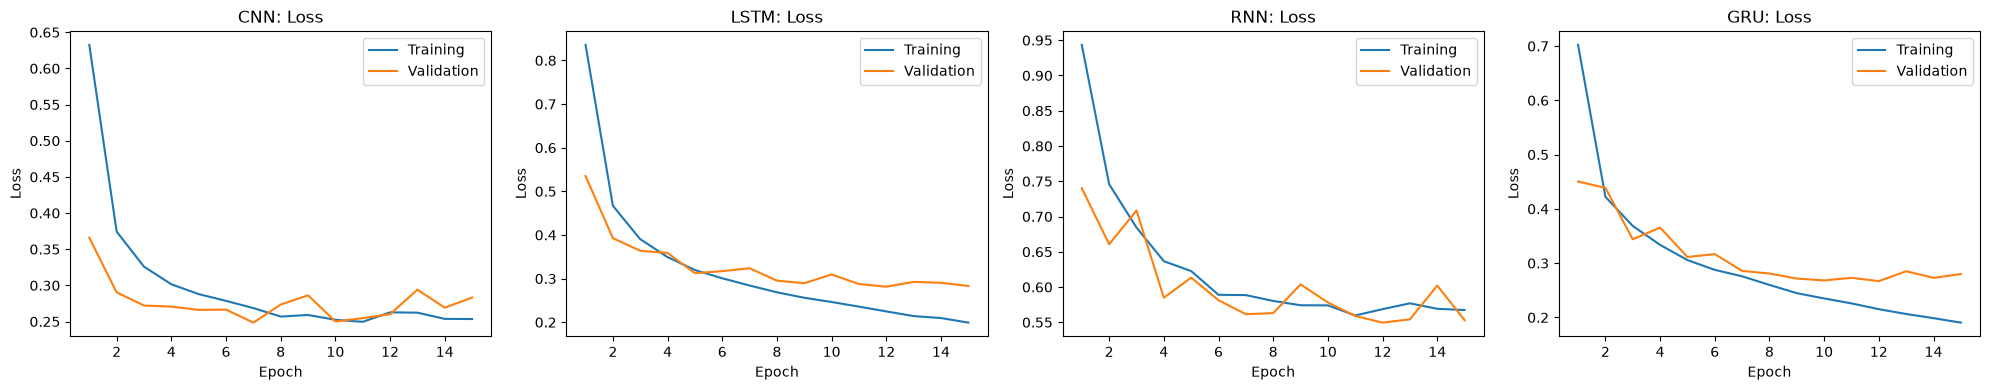

In [ ]:
n = len(history)                                                      # number of models trained so far
fig, axes = plt.subplots(1, n, figsize=(5 * n, 4), squeeze=False)      # one subplot per model, laid out in a row
for ax, (name, (tr, va, _)) in zip(axes[0], history.items()):          # pair each subplot with a model's history
    ax.plot(range(1, len(tr) + 1), tr, label='Training')               # plot the training loss curve
    ax.plot(range(1, len(va) + 1), va, label='Validation')             # plot the validation loss curve
    ax.set_title(f'{name}: Loss'); ax.set_xlabel('Epoch'); ax.set_ylabel('Loss'); ax.legend()  # labels + legend
plt.tight_layout(); plt.show()                                         # layout + render

## 9. Model Evaluation


===== CNN =====
              precision    recall  f1-score   support

 T-shirt/top      0.807     0.897     0.850      1000
     Trouser      0.988     0.988     0.988      1000
    Pullover      0.841     0.869     0.855      1000
       Dress      0.894     0.920     0.907      1000
        Coat      0.855     0.818     0.836      1000
      Sandal      0.978     0.989     0.984      1000
       Shirt      0.770     0.653     0.707      1000
     Sneaker      0.958     0.971     0.964      1000
         Bag      0.970     0.986     0.978      1000
  Ankle boot      0.979     0.960     0.969      1000

    accuracy                          0.905     10000
   macro avg      0.904     0.905     0.904     10000
weighted avg      0.904     0.905     0.904     10000



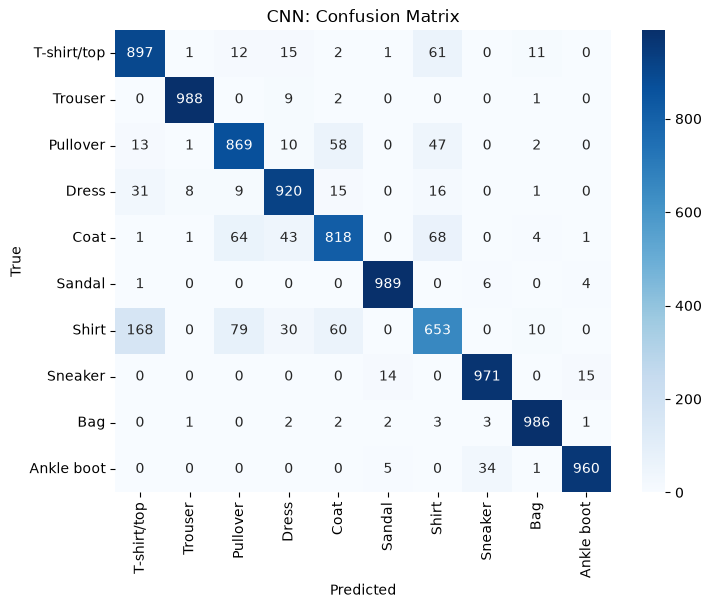


===== LSTM =====
              precision    recall  f1-score   support

 T-shirt/top      0.833     0.850     0.842      1000
     Trouser      0.990     0.979     0.984      1000
    Pullover      0.852     0.792     0.821      1000
       Dress      0.888     0.908     0.898      1000
        Coat      0.785     0.866     0.824      1000
      Sandal      0.969     0.976     0.973      1000
       Shirt      0.747     0.698     0.722      1000
     Sneaker      0.940     0.966     0.953      1000
         Bag      0.982     0.978     0.980      1000
  Ankle boot      0.978     0.950     0.964      1000

    accuracy                          0.896     10000
   macro avg      0.896     0.896     0.896     10000
weighted avg      0.896     0.896     0.896     10000



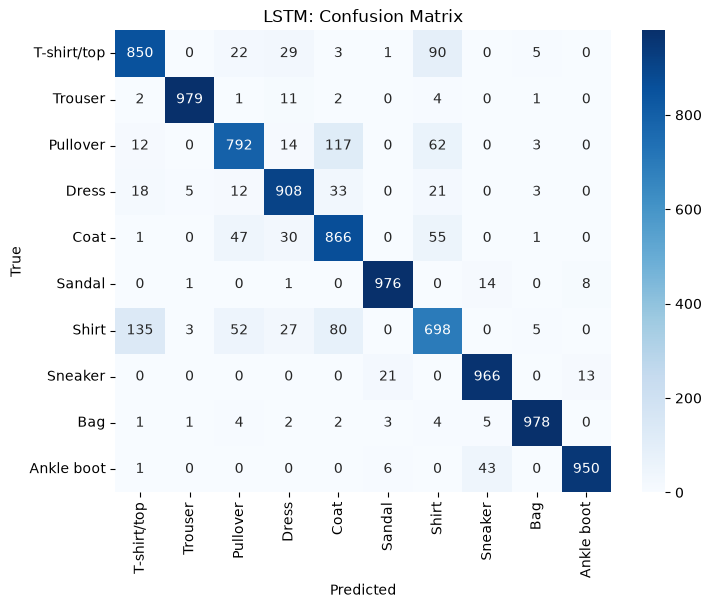


===== RNN =====
              precision    recall  f1-score   support

 T-shirt/top      0.669     0.851     0.749      1000
     Trouser      0.986     0.943     0.964      1000
    Pullover      0.678     0.750     0.712      1000
       Dress      0.753     0.789     0.771      1000
        Coat      0.692     0.732     0.711      1000
      Sandal      0.930     0.905     0.917      1000
       Shirt      0.686     0.358     0.470      1000
     Sneaker      0.895     0.896     0.896      1000
         Bag      0.913     0.925     0.919      1000
  Ankle boot      0.893     0.939     0.916      1000

    accuracy                          0.809     10000
   macro avg      0.810     0.809     0.803     10000
weighted avg      0.810     0.809     0.803     10000



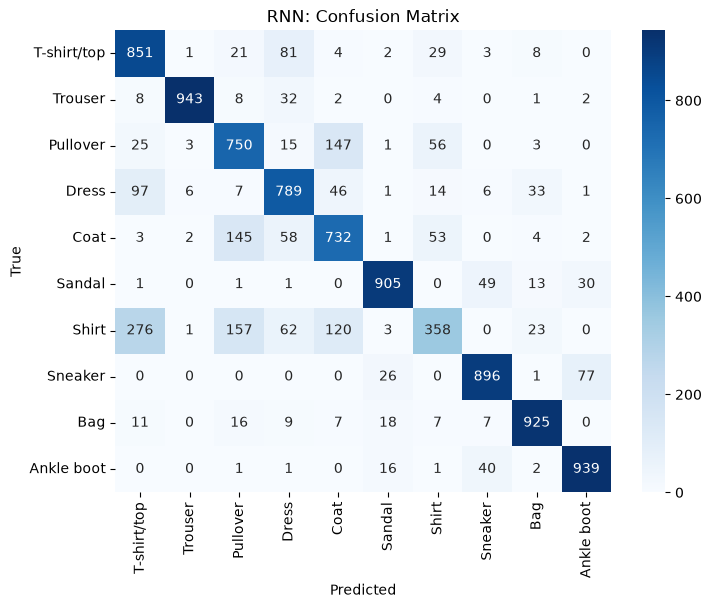


===== GRU =====
              precision    recall  f1-score   support

 T-shirt/top      0.882     0.782     0.829      1000
     Trouser      0.981     0.986     0.984      1000
    Pullover      0.878     0.806     0.840      1000
       Dress      0.888     0.919     0.903      1000
        Coat      0.816     0.852     0.834      1000
      Sandal      0.987     0.952     0.969      1000
       Shirt      0.695     0.764     0.728      1000
     Sneaker      0.941     0.978     0.959      1000
         Bag      0.978     0.985     0.982      1000
  Ankle boot      0.965     0.966     0.966      1000

    accuracy                          0.899     10000
   macro avg      0.901     0.899     0.899     10000
weighted avg      0.901     0.899     0.899     10000



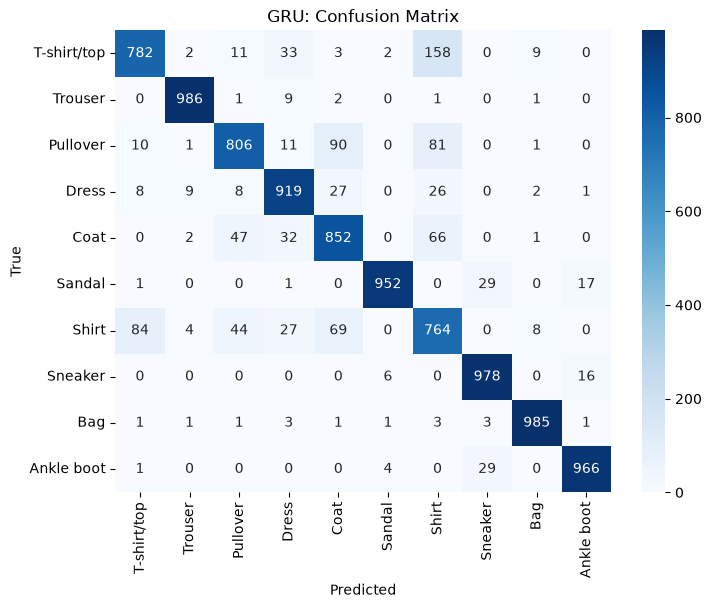

In [ ]:
@torch.no_grad()                                                       # disable gradient tracking during inference
def predict(model, loader):                                            # run a model over a loader, collect predictions
    model.eval()                                                        # disable dropout etc. for evaluation
    preds, labels = [], []                                              # accumulators for predictions and true labels
    for x, y in loader:                                                 # iterate over batches
        out = model(x.to(device))                                      # forward pass on the device
        preds.extend(out.argmax(1).cpu().numpy())                      # predicted class = highest logit, move to CPU
        labels.extend(y.numpy())                                       # true labels for this batch
    return np.array(preds), np.array(labels)                           # return as NumPy arrays

factories = {'CNN': (lambda: SimpleCNN(), 'cnn.pth'),                  # how to build a fresh model instance + where its weights are saved
             'LSTM': (lambda: SeqRNN('lstm'), 'lstm.pth'),
             'RNN': (lambda: SeqRNN('rnn'), 'rnn.pth'),
             'GRU': (lambda: SeqRNN('gru'), 'gru.pth')}

results = {}                                                            # per-model evaluation results
for name in history:                                                    # only evaluate models that were actually trained
    make, path = factories[name]                                       # look up constructor + checkpoint path
    model = make().to(device)                                          # build a fresh model on the device with random weights
    model.load_state_dict(torch.load(path, map_location=device))     # overwrite those random weights with the saved best ones
    preds, labels = predict(model, test_loader)                        # run inference on the held-out test set
    results[name] = dict(acc=(preds == labels).mean(), params=count_params(model),  # test accuracy + parameter count
                         time=history[name][2], preds=preds, labels=labels,         # training time + raw predictions/labels
                         macro_f1=f1_score(labels, preds, average='macro'))          # macro-averaged F1 score

# Detailed report for every trained model
for name in results:                                                    # loop over every evaluated model
    r = results[name]                                                   # shorthand for this model's results
    print(f"\n===== {name} =====")                                      # section header
    print(classification_report(r['labels'], r['preds'], target_names=classes, digits=3))  # precision/recall/F1 per class
    cm = confusion_matrix(r['labels'], r['preds'])                      # count of predicted vs. true class pairs
    plt.figure(figsize=(8, 6))                                          # new figure for the heatmap
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)  # confusion matrix heatmap
    plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(f'{name}: Confusion Matrix')  # axis labels + title
    plt.show()                                                          # render the heatmap

## 10. CNN vs RNN Comparison

In [ ]:
print(f"{'Model':6s} {'Params':>10s} {'Test Acc':>10s} {'Macro F1':>10s} {'Train time (s)':>16s}")  # table header
for name, r in results.items():                                         # one row per model
    print(f"{name:6s} {r['params']:>10,d} {r['acc']:>10.4f} {r['macro_f1']:>10.4f} {r['time']:>16.1f}")  # formatted row

Model      Params   Test Acc   Macro F1   Train time (s)
CNN       901,386     0.9051     0.9037             83.4
LSTM      214,282     0.8963     0.8959             90.9
RNN        54,538     0.8088     0.8026             80.3
GRU       161,034     0.8990     0.8993             89.8


---
# **Assignment 8**

**Dataset: UCI Human Activity Recognition (HAR) using Smartphones**
Link: https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones

Each sample is a **2.56 s window of smartphone sensor data**: 128 time steps x 9 channels (body acc x/y/z, body gyro x/y/z, total acc x/y/z). The task is to classify the activity into 6 classes: WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS, SITTING, STANDING, LAYING.

Because this is **time-series** data, a 1D CNN (local temporal patterns), an RNN (long-range order) and a hybrid of the two are all natural choices, and you will compare them.

**Total: 20 marks**

1. a. Load the UCI HAR dataset using the provided helper cell below, and **combine** the official train and test splits into one dataset. Print the shapes of `X` and `y`. [1 mark]

   b. Standardize each of the 9 channels, then divide the dataset into training, validation and test sets (70%-15%-15%, stratified by activity label). Compute the mean/std on the **training set only**. [1 mark]

   c. Plot the distribution of the activity labels on the training set (bar plot with class names). Plot one example window per activity class (9 channels, 6 subplots). [1 mark]

2. a. Using PyTorch, design a **1D CNN** (`nn.Conv1d`) for activity classification. Use ReLU activation and `MaxPool1d` after every 2 conv layers, following the `SimpleCNN` structure from the demo. Note that `Conv1d` expects input of shape `(batch, channels, time)`. [2 marks]

   b. Design a **recurrent model** using `nn.GRU` or `nn.LSTM` (bidirectional optional) that classifies from the final hidden state. [2 marks]

   c. Design a **hybrid CNN-LSTM**: Conv1d layers extract local features and downsample the sequence, and the LSTM then models the resulting shorter sequence. Experiment with varying depth, number of filters and hidden size to achieve better performance. [2 marks]

   d. Design a **joint (multi-task) loss** for the CNN-LSTM. Add a second output head that predicts whether the activity is **static** (SITTING, STANDING, LAYING) or **dynamic** (the three walking classes). Combine the two losses as $\mathcal{L} = \mathcal{L}_{CE} + \lambda\,\mathcal{L}_{BCE}$. Justify your choice of $\lambda$ using at least 3 values (e.g. 0, 0.5, 1). [2 marks]

3. a. Train all models using SGD with an appropriate minibatch size and learning rate (momentum and gradient clipping are allowed). Record the training and validation loss after every epoch. Save the best checkpoint of each model (lowest validation loss). [3 marks]

   b. Plot the training and validation losses for each model. [1 mark]

4. a. Load the saved models and evaluate them on the test set. For each model report: classification report (accuracy, precision, recall, F1) and the confusion matrix. For the joint-loss model also report the accuracy of the static/dynamic head. [3 marks]

   b. Prepare a comparison table (parameters, test accuracy, macro-F1, training time) for the three models and write a short discussion (4-5 lines): which model is best, which classes are most confused (e.g. SITTING vs STANDING) and why, and what the recurrent component adds over a pure CNN. [2 marks]

**Submission:** a single `.ipynb` with outputs visible. Submit the model files (`.pth`) along with the notebook.

### Provided helper: dataset download and loading (run as is)

In [ ]:
import os, zipfile, urllib.request                                      # filesystem, zip extraction, URL download

HAR_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"  # dataset download URL
SIGNALS = ['body_acc_x', 'body_acc_y', 'body_acc_z',                     # the 9 sensor channel name prefixes
           'body_gyro_x', 'body_gyro_y', 'body_gyro_z',
           'total_acc_x', 'total_acc_y', 'total_acc_z']
ACTIVITIES = ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']  # the 6 class names

def download_har(root='./har'):                                         # download + unzip the HAR dataset if needed
    os.makedirs(root, exist_ok=True)                                    # create the target directory
    zpath = os.path.join(root, 'har.zip')                                # path to the downloaded zip
    if not os.path.exists(zpath):                                       # skip re-downloading if already present
        urllib.request.urlretrieve(HAR_URL, zpath)                      # fetch the zip from the UCI archive
    with zipfile.ZipFile(zpath) as z:                                    # open the outer zip
        z.extractall(root)                                               # extract its contents
    inner = os.path.join(root, 'UCI HAR Dataset.zip')       # the archive contains a nested zip  # path to the nested zip
    if os.path.exists(inner):                                            # only if the nested zip exists
        with zipfile.ZipFile(inner) as z:                                # open the nested zip
            z.extractall(root)                                           # extract it too
    return os.path.join(root, 'UCI HAR Dataset')                        # path to the usable dataset folder

def load_split(base, split):                                            # load one split ('train' or 'test') as arrays
    chans = [np.loadtxt(f"{base}/{split}/Inertial Signals/{s}_{split}.txt") for s in SIGNALS]  # load each of the 9 channel files
    X = np.stack(chans, axis=-1).astype(np.float32)          # (N, 128, 9)  # stack channels into (samples, timesteps, channels)
    y = np.loadtxt(f"{base}/{split}/y_{split}.txt", dtype=int) - 1   # labels 0..5  # load labels, shift from 1-indexed to 0-indexed
    return X, y                                                         # return features and labels

base = download_har()                                                    # ensure dataset is downloaded, get its folder path
X_tr, y_tr = load_split(base, 'train')                                  # load the official training split
X_te, y_te = load_split(base, 'test')                                   # load the official test split
print(X_tr.shape, y_tr.shape, X_te.shape, y_te.shape)       # expect (7352,128,9) (7352,) (2947,128,9) (2947,)  # sanity-check shapes

### Q1 — Data loading, splitting and visualization

In [ ]:
# 1a. Combine train + test

In [ ]:
# 1b. Standardize (train statistics only) and split 70-15-15 (stratified)

In [ ]:
# 1c. Plot label distribution + one example window per activity

### Q2 — Model design

In [ ]:
# 2a. 1D CNN

In [ ]:
# 2b. GRU / LSTM model

In [ ]:
# 2c. Hybrid CNN-LSTM

In [ ]:
# 2d. Multi-task CNN-LSTM (two heads) and joint loss

### Q3 — Training

In [ ]:
# 3a. Training loop (SGD), record losses, save best checkpoints

In [ ]:
# 3b. Plot training / validation losses

### Q4 — Evaluation

In [ ]:
# 4a. Load models, classification report, confusion matrices, static/dynamic accuracy

In [ ]:
# 4b. Comparison table + discussion

**Discussion (Q4b):** *write your answer here*